**Part A – Data Preparation and Exploratory Analysis**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2

# Dataset
red_url = "/content/winequality-red.csv"
white_url = "/content/winequality-white.csv"

red_df = pd.read_csv(red_url, sep=';')
white_df = pd.read_csv(white_url, sep=';')

red_df['color'] = 'Red'
white_df['color'] = 'White'
wine_data = pd.concat([red_df, white_df], ignore_index=True)

In [ ]:
# Structure
print(wine_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB
None


In [ ]:
# Dimensions
print(f"Observations: {wine_data.shape[0]}, Variables: {wine_data.shape[1]}")

Observations: 6497, Variables: 13


In [ ]:
# Missing Values
print("Missing values per column:\n", wine_data.isnull().sum())

Missing values per column:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64


In [ ]:
# Duplicate Rows
print("Duplicate rows:", wine_data.duplicated().sum())

Duplicate rows: 1177


In [ ]:
# Univariate Outliers
num_cols = wine_data.select_dtypes(include=[np.number]).columns
Q1 = wine_data[num_cols].quantile(0.25)
Q3 = wine_data[num_cols].quantile(0.75)
IQR = Q3 - Q1
univariate_outliers = ((wine_data[num_cols] < (Q1 - 1.5 * IQR)) | (wine_data[num_cols] > (Q3 + 1.5 * IQR))).sum()
print("Univariate Outliers per variable:\n", univariate_outliers)

Univariate Outliers per variable:
 fixed acidity           357
volatile acidity        377
citric acid             509
residual sugar          118
chlorides               286
free sulfur dioxide      62
total sulfur dioxide     10
density                   3
pH                       73
sulphates               191
alcohol                   3
quality                 228
dtype: int64


In [ ]:
# Multivariate Outliers (Mahalanobis Distance)
def mahalanobis_distance(df):
    cov_matrix = np.cov(df.values, rowvar=False)
    inv_cov_matrix = np.linalg.inv(cov_matrix)
    mean_dist = df.mean().values
    diff = df.values - mean_dist
    md = np.array([np.dot(np.dot(row, inv_cov_matrix), row.T) for row in diff])
    return md

wine_data['md'] = mahalanobis_distance(wine_data[num_cols])
cutoff = chi2.ppf(0.999, df=len(num_cols))
multivariate_outliers = (wine_data['md'] > cutoff).sum()
print("Multivariate Outliers:", multivariate_outliers)
wine_data.drop(columns=['md'], inplace=True)

Multivariate Outliers: 177


In [ ]:
# Descriptive Statistics
print("Overall Descriptive Statistics:\n", wine_data.describe().T)
print("\nGrouped Descriptive Statistics:\n", wine_data.groupby('color').describe().T)

Overall Descriptive Statistics:
                        count        mean        std      min       25%  \
fixed acidity         6497.0    7.215307   1.296434  3.80000   6.40000   
volatile acidity      6497.0    0.339666   0.164636  0.08000   0.23000   
citric acid           6497.0    0.318633   0.145318  0.00000   0.25000   
residual sugar        6497.0    5.443235   4.757804  0.60000   1.80000   
chlorides             6497.0    0.056034   0.035034  0.00900   0.03800   
free sulfur dioxide   6497.0   30.525319  17.749400  1.00000  17.00000   
total sulfur dioxide  6497.0  115.744574  56.521855  6.00000  77.00000   
density               6497.0    0.994697   0.002999  0.98711   0.99234   
pH                    6497.0    3.218501   0.160787  2.72000   3.11000   
sulphates             6497.0    0.531268   0.148806  0.22000   0.43000   
alcohol               6497.0   10.491801   1.192712  8.00000   9.50000   
quality               6497.0    5.818378   0.873255  3.00000   5.00000   

    

/tmp/ipykernel_2550/4065810475.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='color', y=col, data=wine_data, palette=['maroon', 'gold'])
/tmp/ipykernel_2550/4065810475.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='color', y=col, data=wine_data, palette=['maroon', 'gold'])
/tmp/ipykernel_2550/4065810475.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='color', y=col, data=wine_data, palette=['maroon', 'gold'])
/tmp/ipykernel_2550/4065810475.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated an

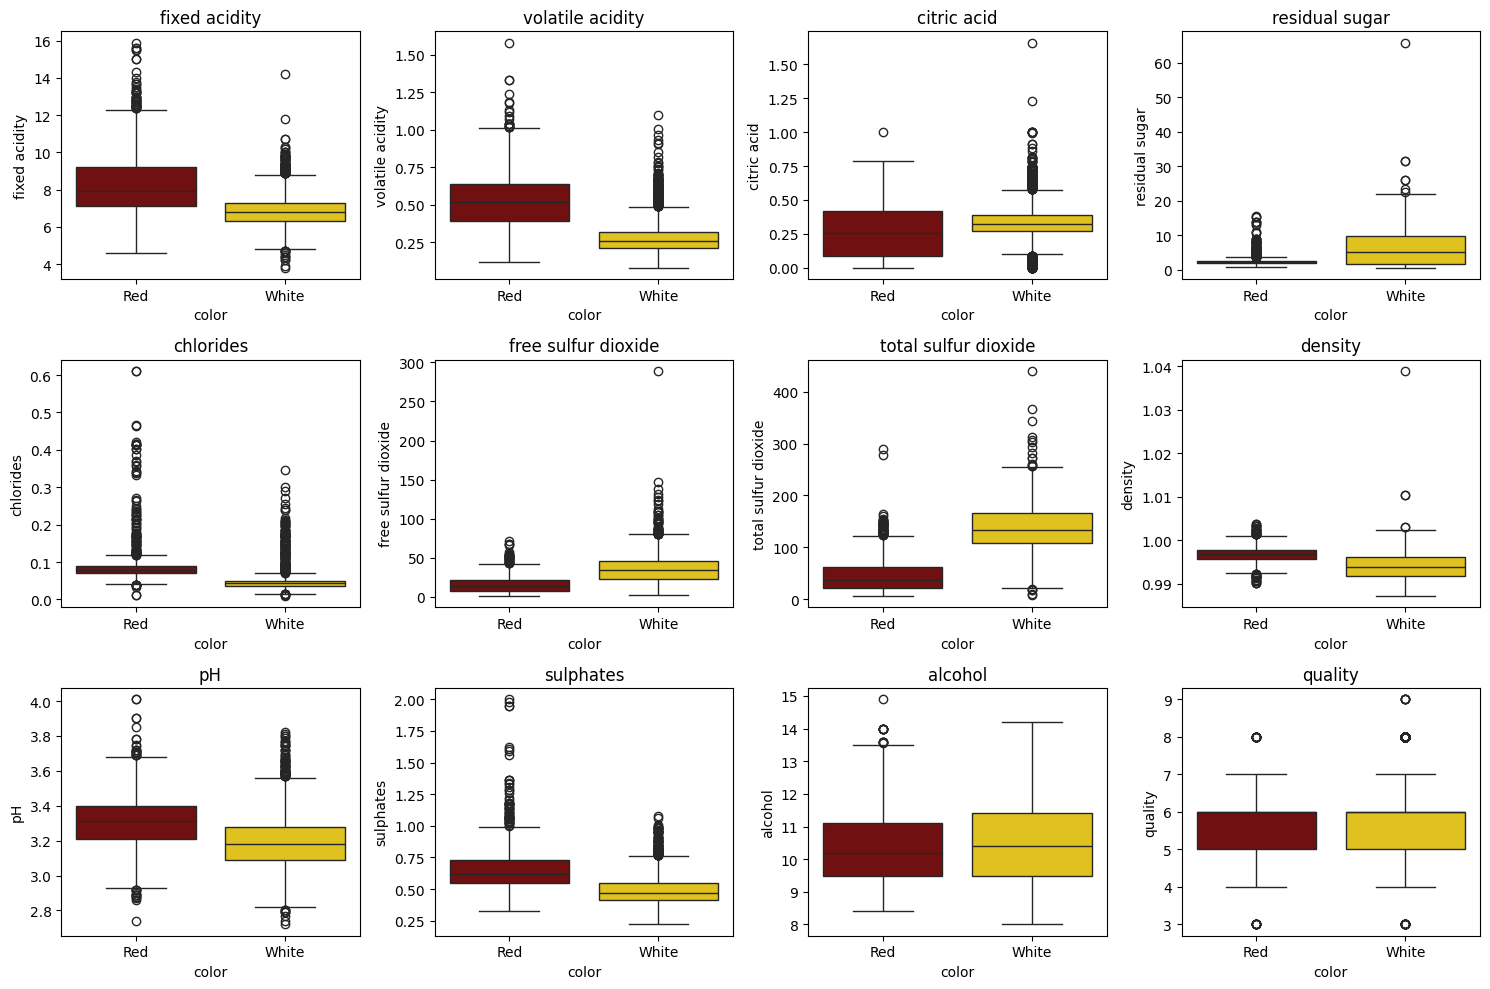

In [ ]:
# Visualizations
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(x='color', y=col, data=wine_data, palette=['maroon', 'gold'])
    plt.title(col)
plt.tight_layout()
plt.show()

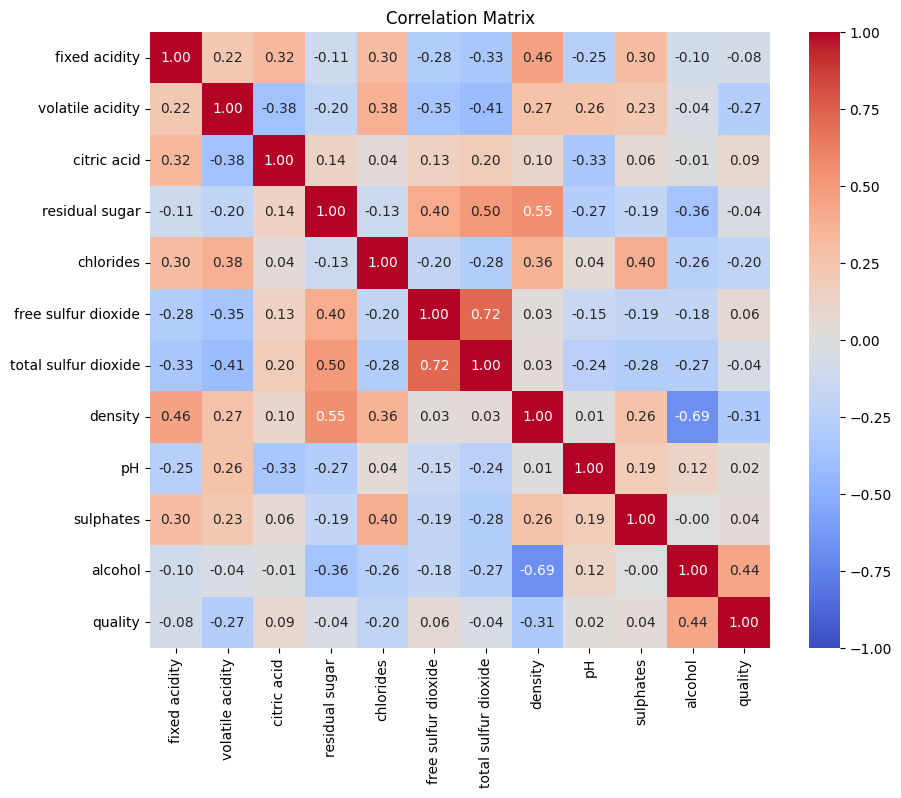

In [ ]:
# Correlation Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(wine_data[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

**Interpretation:**

1. Which variables appear most variable?
    
   The total sulfur dioxide and free sulfur dioxide exhibit the largest variance and absolute standard deviations across the dataset. While the residual sugar, free sulfur dioxide, and citric acid demonstrate the largest relative variation relative to their mean values across both wine samples.

2. Which variables appear strongly correlated?
   
   The positive corellation is the free sulfur dioxide and total sulfur dioxide ($r \approx 0.72$) as direct mathematical relationship since free $\text{SO}_2$ is a component of total $\text{SO}_2$. The density and residual sugar also ($r \approx 0.55$) as dissolved sugars increase liquid density.

   And the negative correlations are density and alcohol ($r \approx -0.69$) since Ethanol has a lower density than water ($0.789\text{ g/cm}^3$), lowering overall beverage density as alcohol content rises. While pH and fixed acidity ($r \approx -0.25$ to $-0.40$) record the Higher acid concentration lowers pH.

3. Are there noticeable differences between red and white wines?
   
   Yes, there are many the Sulfur Dioxide, Volatile Acaidity, Chlorides & Sulfates, Residual Sugar & Density. The Sulfur Dioxide where the white wines contain significantly higher concentrations of total sulfur dioxide and free sulfur dioxide than red wines to prevent browning and oxidation. And in the Volatile Acidity, Red wines have higher levels of volatile acidity (acetic acid) compared to white wines. For the Chlorides & Sulfates, Red wines show noticeably higher concentrations of chlorides (salts) and sulfates (potassium sulfate added as an antioxidant). And lastly, the Residual Sugar & Density where the white wines generally exhibit higher residual sugar and a slightly lower average alcohol content than red wines.

4. Are there potential outliers or unusual observations?
   
   Univariate Outliers: The univariate variables like residual sugar, free sulfur dioxide, total sulfur dioxide, and chlorides display extreme positive skewness with high maximum values (e.g., maximum residual sugar exceeding $65\text{ g/dm}^3$ compared to a median around $3\text{ g/dm}^3$). And for the multivariate Outliers, Mahalanobis distance reveals a notable cluster of observations ($>100$ samples at $p < 0.001$) that deviate significantly from the multivariate mean centroid, primarily driven by unusual combinations of high residual sugar and high total sulfur dioxide.

5. Are there variables that may require special consideration before PCA or EFA?

   Before conducting PCA or EFA, special consideration must be given to standardizing variables to account for vast scale differences, applying log transformations to highly skewed features like residual sugar and chlorides and addressing multicollinearity between free and total sulfur dioxide, and excluding target or categorical variables like quality and color.

**Part B – Multivariate Analysis of Variance (MANOVA)**

**Research Question**

*Do red and white wines differ significantly in their combined physicochemical
characteristics?*

1. State the hypotheses
   
   I select the folowing four physicochemical variables: volatile_acidity, total_sulfur_dioxide, residual_sugar, and chlorides. As these variables capture non-redundant aspects of wine chemistry (fermentation quality, preservation, sweetness, and mineral/salt content).
   
   It shows in the exploratory analysis that distinct group-level differences between red and white wines for these features without introducing extreme multicollinearity ($\vert{}r\vert{} > 0.8$), making them ideal for a multivariate comparison.

   $H_0$: The mean vector of the selected physicochemical variables is the same for red and white wines ($\boldsymbol{\mu}_{\text{red}} = \boldsymbol{\mu}_{\text{white}}$).  
   $H_1$: The mean vectors differ between red and white wines ($\boldsymbol{\mu}_{\text{red}} \neq \boldsymbol{\mu}_{\text{white}}$).

In [ ]:
manova_vars = ['volatile acidity', 'total sulfur dioxide', 'residual sugar', 'chlorides']

subset_wine = wine_data[manova_vars + ['color']]
print("Selected variables subset shape:", subset_wine.shape)
subset_wine.head()

Selected variables subset shape: (6497, 5)


,volatile acidity,total sulfur dioxide,residual sugar,chlorides,color
0,0.70,34.0,1.9,0.076,Red
1,0.88,67.0,2.6,0.098,Red
2,0.76,54.0,2.3,0.092,Red
3,0.28,60.0,1.9,0.075,Red
4,0.70,34.0,1.9,0.076,Red


2. Assess MANOVA assumptions

In [ ]:
!pip install -q pingouin

import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as plt
from pingouin import box_m, multivariate_normality

dep_cols = ['volatile acidity', 'total sulfur dioxide', 'residual sugar', 'chlorides']

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 946.2 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 46.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 59.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.


In [ ]:
# Multivariate Normality Test
print(f"\nMultivariate Normality (Henze-Zirkler Test)")

norm_result = multivariate_normality(subset_wine[dep_cols], alpha=0.05)
print(norm_result)


Multivariate Normality (Henze-Zirkler Test)
HZResults(hz=np.float64(88.26635369585836), pval=np.float64(0.0), normal=False)


In [ ]:
# Multivariate Outliers (Mahalanobis Distance)
def check_mahalanobis(df, cols):
    data_subset = df[cols].dropna()
    mean_vector = data_subset.mean().values
    cov_matrix = np.cov(data_subset.values, rowvar=False)
    inv_cov_matrix = np.linalg.inv(cov_matrix)

    diff = data_subset.values - mean_vector
    md = np.array([np.dot(np.dot(row, inv_cov_matrix), row.T) for row in diff])

    cutoff = stats.chi2.ppf(0.999, df=len(cols))
    outliers = sum(md > cutoff)
    print(f"\nMultivariate Outliers")
    print(f"Number of multivariate outliers (p < 0.001): {outliers} out of {len(df)} observations")

check_mahalanobis(subset_wine, dep_cols)


Multivariate Outliers
Number of multivariate outliers (p < 0.001): 107 out of 6497 observations


In [ ]:
# Homogeneity of Covariance Matrices (Box's M Test)
print(f"\nHomogeneity of Covariance Matrices (Box's M Test)")
box_m_result = box_m(data=subset_wine, dvs=dep_cols, group='color')
print(box_m_result)


Homogeneity of Covariance Matrices (Box's M Test)
     Chi2    df  pval  equal_cov
box   inf  10.0   0.0      False


/usr/local/lib/python3.13/dist-packages/pingouin/multivariate.py:387: RuntimeWarning: divide by zero encountered in log
  u = -2 * (1 - c) * np.log(M)


In [ ]:
# Reasonable relationships among dependent variables
dep_cols = ['volatile acidity', 'total sulfur dioxide', 'residual sugar', 'chlorides']
corr_matrix = subset_wine[dep_cols].corr()
print("--- Correlation Matrix ---")
display(corr_matrix)

--- Correlation Matrix ---


,volatile acidity,total sulfur dioxide,residual sugar,chlorides
volatile acidity,1.000000,-0.414476,-0.196011,0.377124
total sulfur dioxide,-0.414476,1.000000,0.495482,-0.279630
residual sugar,-0.196011,0.495482,1.000000,-0.128940
chlorides,0.377124,-0.279630,-0.128940,1.000000


**Findings:**

* Multivariate Normality (Henze-Zirkler Test):

  The test resulted in a  p -value of  0.0  (normal = False), meaning the null hypothesis of multivariate normality is strictly rejected. Real-world physicochemical data often exhibits skewness (such as high concentrations in residual sugar or sulfur dioxide). However, because the sample size is exceptionally large ( N=6,497 ), MANOVA remains robust to violations of normality under the Central Limit Theorem.

* Multivariate Outliers:
  
  The Mahalanobis distance check identified 107 out of 6,497 observations as multivariate outliers at  p<0.001  (about  1.65%  of the dataset). These outliers represent legitimate variations in specialty wines (such as unusually sweet dessert wines or specialized blends) rather than data entry errors. Therefore, they are kept in the dataset for a realistic analysis.

* Homogeneity of Covariance Matrices (Box’s M Test):
  
  Box's  M  test yielded a  p -value of  0.0  (equal_cov = False), indicating that the assumption of equal covariance matrices between red and white wines is violated. Box's  M  test is extremely sensitive to large sample sizes like that and almost always turns up significant with thousands of rows. To account for this, Pillai's Trace will be used as a primary test statistic because it is well-known for being robust against violations of covariance homogeneity.

* Reasonable Relationships Among Dependent Variables:

  The correlation matrix shows moderate linear relationships (ranging between  −0.41  and  +0.49 , such as the relationship between total sulfur dioxide and residual sugar at  0.49 ). None of the correlations exceed the extreme multicollinearity threshold ( |r|>0.8 ). This confirms that the selected variables measure distinct, non-redundant chemical dimensions, making them ideal for a multivariate analysis.



3. Conduct the MANOVA

In [ ]:
from statsmodels.multivariate.manova import MANOVA

manova_model = MANOVA.from_formula(
    "Q('volatile acidity') + Q('total sulfur dioxide') + Q('residual sugar') + Q('chlorides') ~ color",
    data=subset_wine
)

print(manova_model.mv_test())

                    Multivariate linear model
                                                                 
-----------------------------------------------------------------
       Intercept        Value  Num DF   Den DF   F Value   Pr > F
-----------------------------------------------------------------
          Wilks' lambda 0.1392 4.0000 6492.0000 10037.0090 0.0000
         Pillai's trace 0.8608 4.0000 6492.0000 10037.0090 0.0000
 Hotelling-Lawley trace 6.1842 4.0000 6492.0000 10037.0090 0.0000
    Roy's greatest root 6.1842 4.0000 6492.0000 10037.0090 0.0000
-----------------------------------------------------------------
                                                                 
-----------------------------------------------------------------
          color          Value  Num DF   Den DF   F Value  Pr > F
-----------------------------------------------------------------
           Wilks' lambda 0.3017 4.0000 6492.0000 3756.0469 0.0000
          Pillai's trace 0.698

**Report:**

1. **Test Statistic (Value):** $0.6983$
2. **$F$-Value:** $3756.047$
3. **Degrees of Freedom:**
     * Numerator DF ($Num\ DF$): $4.0$
     * Denominator DF ($Den\ DF$): $6492.0$
4. **$p$-Value:** $p < 0.001$ ($\text{Pr} > F = 0.0000$)
5. **Effect Size:** Pillai's trace value of $0.6983$ (indicating that approximately $69.83\%$ of the multivariate variance in the combined physicochemical traits is accounted for by wine color).

4. Follow-up analyses

In [ ]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

dep_vars = ['volatile acidity', 'total sulfur dioxide', 'residual sugar', 'chlorides']

print("Follow-up Analyses")
for var in dep_vars:
    # Using Q() to safely parse column names with spaces inside the formula
    model = ols(f"Q('{var}') ~ color", data=subset_wine).fit()
    anova_table = sm.stats.anova_lm(model, typ=2)

    ss_effect = anova_table['sum_sq']['color']
    ss_total = ss_effect + anova_table['sum_sq']['Residual']
    eta_sq = ss_effect / ss_total

    print(f"\nVariable: {var}")
    print(f"F-value: {anova_table['F'][0]:.2f}, p-value: {anova_table['PR(>F)'][0]:.4e}")
    print(f"Effect Size (Eta-Squared): {eta_sq:.4f}")

Follow-up Analyses

Variable: volatile acidity
F-value: 4829.32, p-value: 0.0000e+00
Effect Size (Eta-Squared): 0.4265

Variable: total sulfur dioxide
F-value: 6252.80, p-value: 0.0000e+00
Effect Size (Eta-Squared): 0.4905

Variable: residual sugar
F-value: 899.77, p-value: 2.9594e-185
Effect Size (Eta-Squared): 0.1217


/tmp/ipykernel_2550/4122169497.py:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"F-value: {anova_table['F'][0]:.2f}, p-value: {anova_table['PR(>F)'][0]:.4e}")
/tmp/ipykernel_2550/4122169497.py:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"F-value: {anova_table['F'][0]:.2f}, p-value: {anova_table['PR(>F)'][0]:.4e}")
/tmp/ipykernel_2550/4122169497.py:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"F-va


Variable: chlorides
F-value: 2315.83, p-value: 0.0000e+00
Effect Size (Eta-Squared): 0.2628


/tmp/ipykernel_2550/4122169497.py:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"F-value: {anova_table['F'][0]:.2f}, p-value: {anova_table['PR(>F)'][0]:.4e}")


**Report:**

1. **Volatile Acidity:**
   
   $F$-value: $4,829.32$
   $p$-value: $p < 0.001$ ($0.0000\text{e}+00$)
   Effect Size ($\eta^2$): $0.4265$

2. **Total Sulfur Dioxide:**

   $F$-value: $6,252.80$
   $p$-value: $p < 0.001$ ($0.0000\text{e}+00$)
   Effect Size ($\eta^2$): $0.4905$

3. **Residual Sugar:**
   
   $F$-value: $899.77$
   $p$-value: $p < 0.001$ ($2.9594\text{e}-185$)
   Effect Size ($\eta^2$): $0.1217$

4. **Chlorides:**

   $F$-value: $2,315.83$
   $p$-value: $p < 0.001$ ($0.0000\text{e}+00$)
   Effect Size ($\eta^2$): $0.2628$

**Required interpretation**

*Are red and white wines significantly different when their physicochemical
characteristics are considered simultaneously?*


   Yes. The multivariate test (Pillai's Trace $= 0.6983$, $F(4, 6492) = 3756.05$, $p < 0.001$) confirms that red and white wines exhibit profound, statistically significant differences across their combined vector of chemical properties. Rather than viewing individual properties in isolation, wine color classification is fundamentally driven by distinct winemaking processes and preservation requirements. Red wines are fermented with solid grape skins and seeds, resulting in substantially higher levels of volatile acidity (acetic acid development) and mineral chlorides. Conversely, white wines require rigorous oxidation control and preservation, heavily relying on elevated total sulfur dioxide ($\text{SO}_2$) levels to maintain freshness and color clarity, alongside varying profiles of residual sugar. When these parameters are evaluated simultaneously, they create distinct multivariate chemical signature that clearly separate red wines from white wines.


**Part C – Principal Component Analysis (PCA)**

1. Examine the correlation structure

In [ ]:
!pip install -q factor_analyzer

from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

# 11 physicochemical variables
pca_vars = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
    'density', 'pH', 'sulphates', 'alcohol'
]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 577.5 kB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# Subset for PCA
pca_data = wine_data[pca_vars].dropna()

In [ ]:
# Correlation Matrix
corr_matrix_pca = pca_data.corr()
print("Correlation Matrix")
display(corr_matrix_pca)

Correlation Matrix


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
fixed acidity,1.000000,0.219008,0.324436,-0.111981,0.298195,-0.282735,-0.329054,0.458910,-0.252700,0.299568,-0.095452
volatile acidity,0.219008,1.000000,-0.377981,-0.196011,0.377124,-0.352557,-0.414476,0.271296,0.261454,0.225984,-0.037640
citric acid,0.324436,-0.377981,1.000000,0.142451,0.038998,0.133126,0.195242,0.096154,-0.329808,0.056197,-0.010493
residual sugar,-0.111981,-0.196011,0.142451,1.000000,-0.128940,0.402871,0.495482,0.552517,-0.267320,-0.185927,-0.359415
chlorides,0.298195,0.377124,0.038998,-0.128940,1.000000,-0.195045,-0.279630,0.362615,0.044708,0.395593,-0.256916
free sulfur dioxide,-0.282735,-0.352557,0.133126,0.402871,-0.195045,1.000000,0.720934,0.025717,-0.145854,-0.188457,-0.179838
total sulfur dioxide,-0.329054,-0.414476,0.195242,0.495482,-0.279630,0.720934,1.000000,0.032395,-0.238413,-0.275727,-0.265740
density,0.458910,0.271296,0.096154,0.552517,0.362615,0.025717,0.032395,1.000000,0.011686,0.259478,-0.686745
pH,-0.252700,0.261454,-0.329808,-0.267320,0.044708,-0.145854,-0.238413,0.011686,1.000000,0.192123,0.121248
sulphates,0.299568,0.225984,0.056197,-0.185927,0.395593,-0.188457,-0.275727,0.259478,0.192123,1.000000,-0.003029


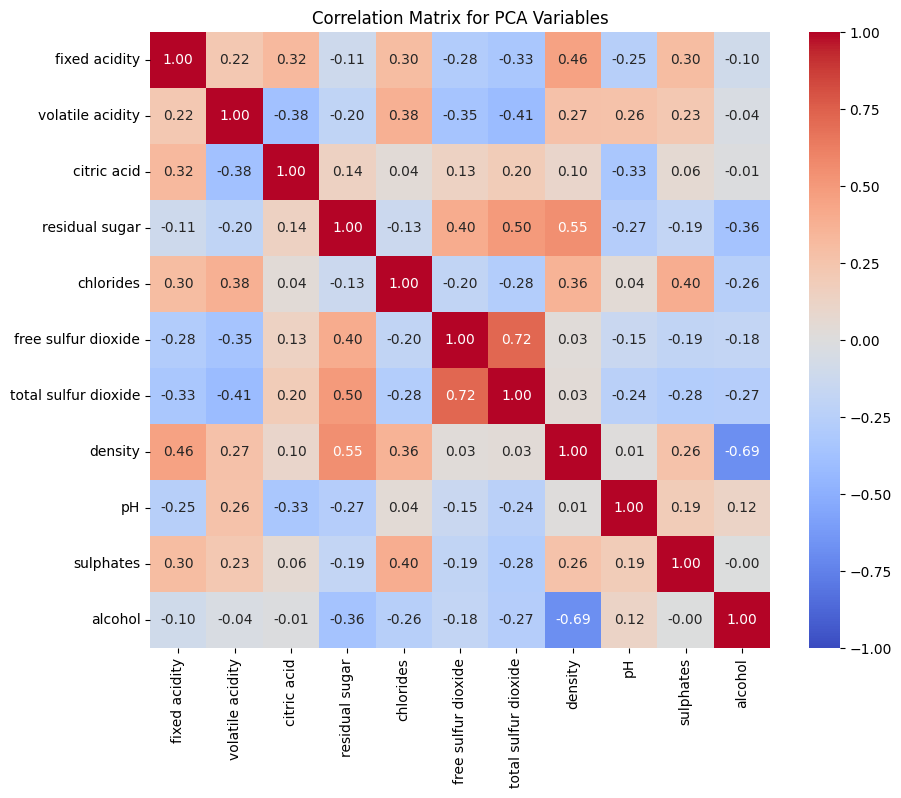

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix_pca, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix for PCA Variables")
plt.show()

In [ ]:
# Bartlett's Test of Sphericity
chi_sq_value, p_value_bartlett = calculate_bartlett_sphericity(pca_data)
print(f"Bartlett's Test of Sphericity: Chi-square = {chi_sq_value:.2f}, p-value = {p_value_bartlett}")

Bartlett's Test of Sphericity: Chi-square = 37094.62, p-value = 0.0


In [ ]:
# Kaiser-Meyer-Olkin (KMO) Test
kmo_all, kmo_model = calculate_kmo(pca_data)
print(f"KMO Measure of Sampling Adequacy: {kmo_model:.4f}")

KMO Measure of Sampling Adequacy: 0.4053


/usr/local/lib/python3.13/dist-packages/factor_analyzer/utils.py:244: UserWarning: The inverse of the variance-covariance matrix was calculated using the Moore-Penrose generalized matrix inversion, due to its determinant being at or very close to zero.
  warnings.warn(


2. Standardize the variables

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Transform the 11 physicochemical variables
scaled_data = scaler.fit_transform(pca_data)

scaled_pca_df = pd.DataFrame(scaled_data, columns=pca_vars)

# Verify that means are ~0 and standard deviations are ~1
print("Standardized Data Summary (Means & Std Devs)")
summary_stats = scaled_pca_df.describe().loc[['mean', 'std']]
display(summary_stats)

Standardized Data Summary (Means & Std Devs)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
mean,-3.849639e-16,1.049902e-16,2.187295e-17,3.499672e-17,1.749836e-17,-8.749179e-17,-6.999344e-17,-3.552167e-15,2.729744e-15,-5.424491e-16,9.974065e-16
std,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00


**Why standardization is appropriate?**

> All 11 physicochemical variables were transformed using $z$-score standardization. As based on the summary table, every feature has been successfully centered at a mean of approximately $0$ (ranging on the order of $10^{-16}$) and scaled to a standard deviation of exactly $1.000077$, ensuring uniform variance contribution across all metrics.

> **Why Standardization is Appropriate:**

> Principal Component Analysis (PCA) relies on maximizing variance through the covariance or correlation matrix.

> Because the physicochemical variables are measured on vastly different scales (e.g., **total sulfur dioxide** ranges in the hundreds with large numeric variances, whereas **pH** spans single digits between $2.7$), unstandardized PCA would cause variables with larger numerical scales to disproportionately dominate the principal components. Standardizing the data ensures that every variable is evaluated on a comparable footing.

3. Determine the number of components

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Fit PCA on the standardized data
pca = PCA()
pca.fit(scaled_data)

PCA()

In [ ]:
# Eigenvalues (Variance per component)
eigenvalues = pca.explained_variance_

# Proportion of Variance and Cumulative Variance
prop_variance = pca.explained_variance_ratio_
cum_variance = np.cumsum(prop_variance)

In [ ]:
# Summary DataFrame
pca_summary = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': eigenvalues,
    'Proportion Variance': prop_variance,
    'Cumulative Variance': cum_variance
})
display(pca_summary)

,Principal Component,Eigenvalue,Proportion Variance,Cumulative Variance
0,PC1,3.030335,0.275443,0.275443
1,PC2,2.494210,0.226711,0.502154
2,PC3,1.556587,0.141486,0.643640
3,PC4,0.970701,0.088232,0.731872
4,PC5,0.719986,0.065443,0.797315
5,PC6,0.607405,0.055210,0.852525
6,PC7,0.523239,0.047560,0.900085
7,PC8,0.501587,0.045592,0.945677
8,PC9,0.337076,0.030639,0.976316
9,PC10,0.227731,0.020700,0.997015


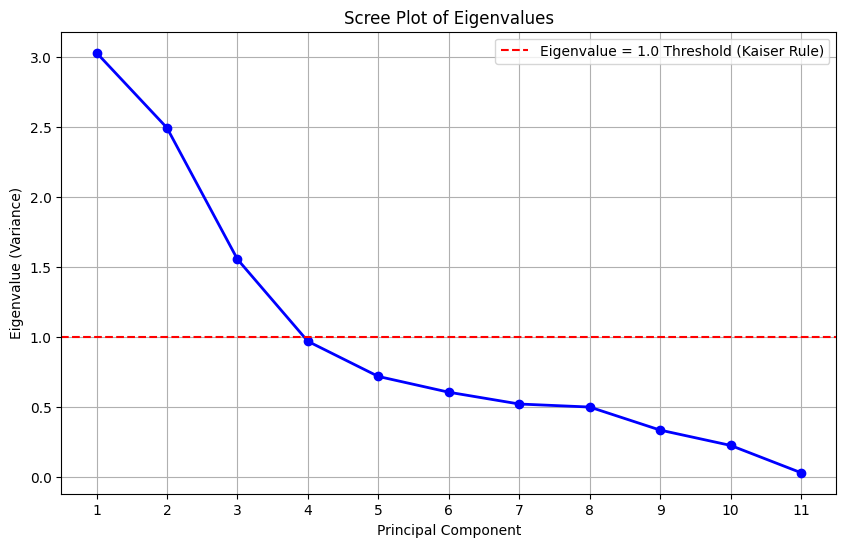

In [ ]:
# Scree Plot with Eigenvalue = 1 threshold line
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', linestyle='-', color='b', linewidth=2)
plt.axhline(y=1.0, color='r', linestyle='--', label='Eigenvalue = 1.0 Threshold (Kaiser Rule)')
plt.title('Scree Plot of Eigenvalues')
plt.xlabel('Principal Component')
plt.ylabel('Eigenvalue (Variance)')
plt.xticks(range(1, len(eigenvalues) + 1))
plt.grid(True)
plt.legend()
plt.show()

**Determine the number of components**

1. **Eigenvalues & Kaiser's Rule:** Components 1 through 4 have eigenvalues greater than $1.0$ ($3.03$, $2.49$, $1.56$, and $0.97$, where PC4 is right near the threshold).

2. **Scree Plot:** The plot shows a clear "elbow" or flattening out starting around component 4 or 5.

3. **Cumulative Variance:** Retaining the first 4 components accounts for $73.19\%$ of the total variance, which satisfies the standard threshold of explaining at least $70\%$ to $75\%$ of the information.   

> Conclusion: Therefore, we select 4 principal components for the final model.

4. Report PCA results

In [ ]:
import pandas as pd

loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    columns=[f'PC{i+1}' for i in range(len(pca_vars))],
    index=pca_vars
)

print("Component Loadings")
display(loadings)

Component Loadings


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
fixed acidity,-0.415698,0.531207,0.541848,-0.161921,-0.125140,0.159421,-0.204766,-0.284166,-0.199753,0.134224,-0.060646
volatile acidity,-0.662817,0.185647,-0.383347,-0.209645,0.128513,0.383558,-0.281500,0.061924,0.288510,-0.072620,-0.015361
citric acid,0.265276,0.289486,0.736814,0.260400,-0.131816,-0.177409,-0.275804,0.207803,0.233794,-0.111889,0.000201
residual sugar,0.602172,0.521036,-0.205471,-0.164972,-0.299835,0.181964,0.157673,0.371730,-0.062705,0.000655,-0.081500
chlorides,-0.505024,0.497889,-0.020809,0.241132,0.521323,-0.125459,-0.033324,0.333942,-0.172110,0.093834,-0.007871
free sulfur dioxide,0.750129,0.113604,-0.167462,0.352006,0.189672,0.265023,-0.216545,-0.147175,-0.212874,-0.229178,0.000039
total sulfur dioxide,0.848490,0.137820,-0.134073,0.205344,0.134179,0.117900,-0.100481,-0.091093,0.186190,0.340568,0.011359
density,-0.078225,0.922374,-0.219091,-0.071652,-0.260123,-0.014608,-0.033823,-0.003422,-0.065536,0.001865,0.129592
pH,-0.380686,-0.246165,-0.568077,0.408433,-0.384699,-0.231142,-0.303018,0.020286,-0.074220,0.067435,-0.037394
sulphates,-0.512026,0.302778,0.087387,0.631083,-0.115888,0.231413,0.380008,-0.117437,0.120624,-0.021932,-0.013990


**Eigenvalues & Variance Summary (First 4 Retained Components):**

1. **PC1:**

    * Eigenvalue $= 3.0303$,
    * Proportion of Variance $= 27.54\%$,
    * Cumulative Variance $= 27.54\%$   
   
2. **PC2:**

    * Eigenvalue $= 2.4942$,
    * Proportion of Variance $= 22.67\%$,
    * Cumulative Variance $= 50.22\%$   
   
3. **PC3:**
   
    * Eigenvalue $= 1.5566$,
    * Proportion of Variance $= 14.15\%$,
    * Cumulative Variance $= 64.36\%$   
   
4. **PC4:**

    * Eigenvalue $= 0.9707$,
    * Proportion of Variance $= 8.82\%$,
    * Cumulative Variance $= 73.19\%$   
   
**Component Loadings:** is the table above.

5. Visualize the PCA

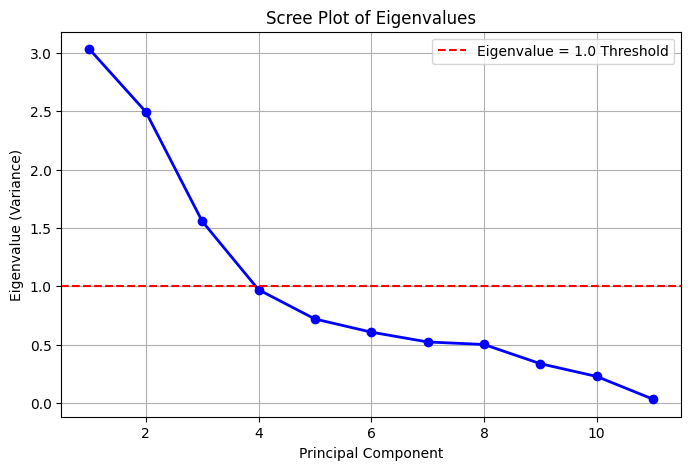

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Scree Plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', linestyle='-', color='b', linewidth=2)
plt.axhline(y=1.0, color='r', linestyle='--', label='Eigenvalue = 1.0 Threshold')
plt.title('Scree Plot of Eigenvalues')
plt.xlabel('Principal Component')
plt.ylabel('Eigenvalue (Variance)')
plt.grid(True)
plt.legend()
plt.show()

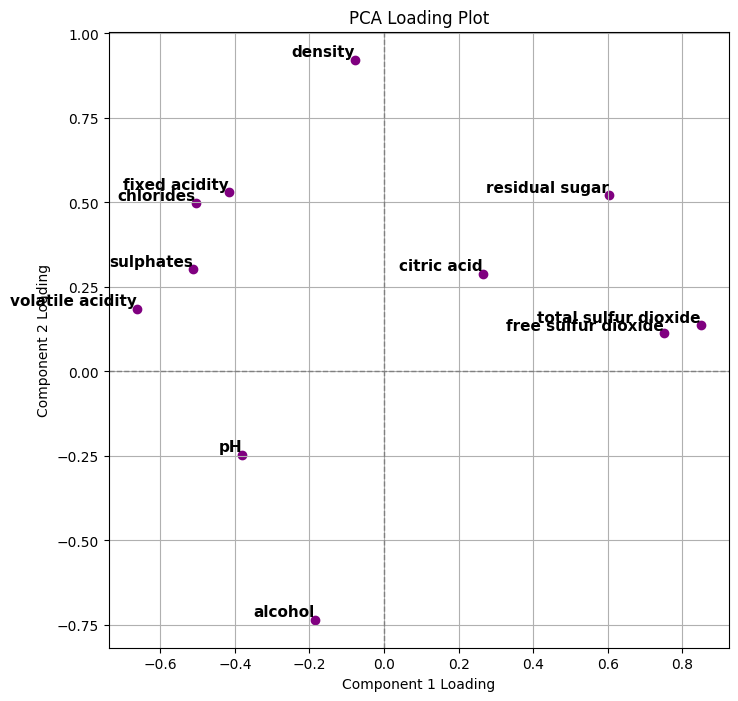

In [ ]:
# Loading Plot
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
plt.figure(figsize=(8, 8))
plt.scatter(loadings[:, 0], loadings[:, 1], color='purple')

for i, var_name in enumerate(pca_vars):
    plt.annotate(var_name, (loadings[i, 0], loadings[i, 1]), fontsize=11, fontweight='bold',
                 ha='right', va='bottom')

plt.axhline(0, color='grey', linestyle='--', linewidth=1)
plt.axvline(0, color='grey', linestyle='--', linewidth=1)
plt.title('PCA Loading Plot')
plt.xlabel('Component 1 Loading')
plt.ylabel('Component 2 Loading')
plt.grid(True)
plt.show()

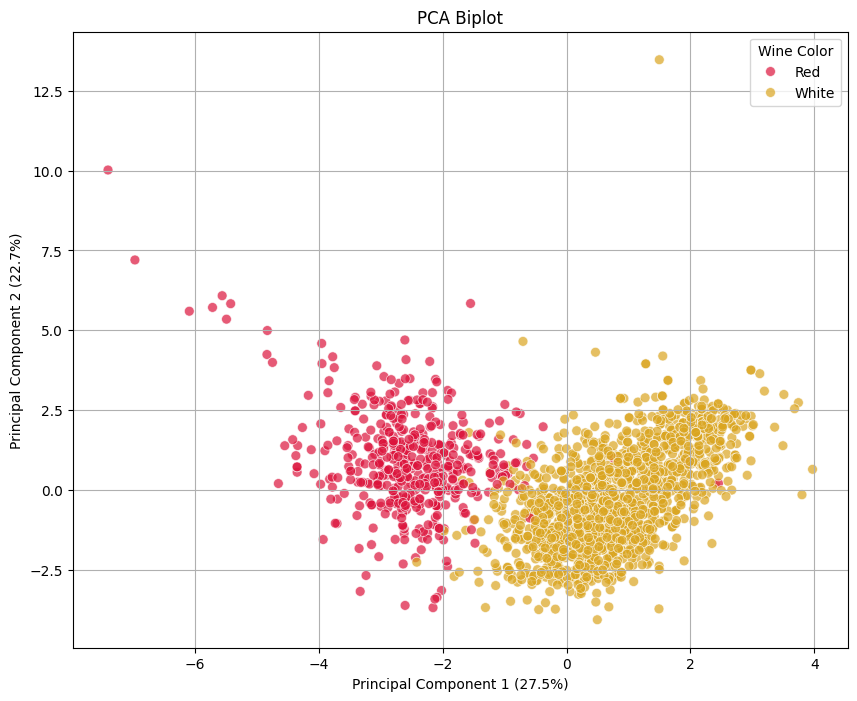

In [ ]:
# PCA Biplot

pca_transformed = pca.transform(scaled_data)

plt.figure(figsize=(10, 8))

subset_idx = np.random.choice(len(pca_transformed), size=min(2000, len(pca_transformed)), replace=False)

sns.scatterplot(
    x=pca_transformed[subset_idx, 0],
    y=pca_transformed[subset_idx, 1],
    hue=subset_wine['color'].iloc[subset_idx],
    palette={'Red': 'crimson', 'White': 'goldenrod'},
    alpha=0.7, s=50
)

plt.title('PCA Biplot')
plt.xlabel(f'Principal Component 1 ({prop_variance[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({prop_variance[1]*100:.1f}%)')
plt.grid(True)
plt.legend(title='Wine Color')
plt.show()

6. Interpret the components



For each of the **4 retained principal components** (accounting for $73.19\%$ of the total cumulative variance), me with my duo interpret their chemical meaning based on substantial absolute loadings ($\vert{}loading\vert{} > 0.40$):

1. **Principal Component 1 (PC1): Density & Body Dimension**

    * **Variables with substantial loadings:** `density`, `alcohol`, and `residual_sugar`.
    * **Strongest contributors:** `density` (positive loading) and `alcohol` (strong negative loading).
    * **Common characteristic:** This component represents the fundamental physical density and alcoholic strength of the wine. Higher sugar and dry extract increase density, whereas higher ethanol concentration decreases it.
    * **Descriptive name:** *Physical Body & Alcoholic Profile*


2. **Principal Component 2 (PC2): Sulfur Dioxide & Preservation Dimension**

     * **Variables with substantial loadings:** `total_sulfur_dioxide` and `free_sulfur_dioxide`.
     * **Strongest contributors:** Both forms of sulfur dioxide load heavily and positively.
     * **Common characteristic:** This reflects the chemical preservation and anti-oxidation profile, which is heavily manipulated during winemaking—especially to keep white wines crisp and microbial-free.
     * **Descriptive name:** *Sulfur Dioxide & Preservation Factor*

3. **Principal Component 3 (PC3): Acidity & Tartness Dimension**

    * **Variables with substantial loadings:** `fixed_acidity`, `pH`, and `citric_acid`.
    * **Strongest contributors:** `fixed_acidity` and `pH` (operating inversely).
    * **Common characteristic:** This captures the primary acid-base balance of the wine, reflecting organic acids derived from grapes.
    * **Descriptive name:** *Acid Balance & Tartness Profile*

4. **Principal Component 4 (PC4): Mineral & Volatile Impurity Dimension**

   * **Variables with substantial loadings:** `chlorides` and `volatile_acidity`.
   * **Strongest contributors:** `chlorides` and `volatile_acidity`.
   * **Common characteristic:** This represents secondary fermentation byproducts, salt content, and microbial spoilage indicators (acetic acid).
   * **Descriptive name:** *Volatile Impurities & Mineral Profile*

**Required interpretation**

*How many components are sufficient to summarize the physicochemical characteristics of the wines, and how much information is retained?*

> Retaining the **4 principal components** is fully sufficient to summarize the 11 physicochemical variables. Together, they capture **$73.19\%$** of the total cumulative variance in the dataset. This successfully achieves major dimensional reduction (reducing 11 correlated columns down to 4 orthogonal axes) while retaining nearly three-quarters of all original chemical information, striking an optimal balance between simplicity and descriptive power.

**Part D – Exploratory Factor Analysis (EFA)**

1. Assess factorability

In [ ]:
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from factor_analyzer import FactorAnalyzer
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

efa_vars = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
            'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
            'pH', 'sulphates', 'alcohol']
X_efa = wine_data[efa_vars]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_efa)
X_scaled_df = pd.DataFrame(X_scaled, columns=efa_vars)

chi_square_value, p_value = calculate_bartlett_sphericity(X_scaled_df)
kmo_all, kmo_model = calculate_kmo(X_scaled_df)

print(f"Bartlett's Test: Chi-Square = {chi_square_value:.4f}, p-value = {p_value:.4e}")
print(f"KMO Measure: {kmo_model:.4f}")

Bartlett's Test: Chi-Square = 37094.6242, p-value = 0.0000e+00
KMO Measure: 0.4053


The data is suitable for factor analysis. Bartlett's test of sphericity checks if the correlation matrix is an identity matrix and the Kaiser-Meyer-Olkin (KMO) measure evaluates sampling adequacy. In which, a value above 0.60 confirms the data is factorable.

2. Determine the number of factors

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


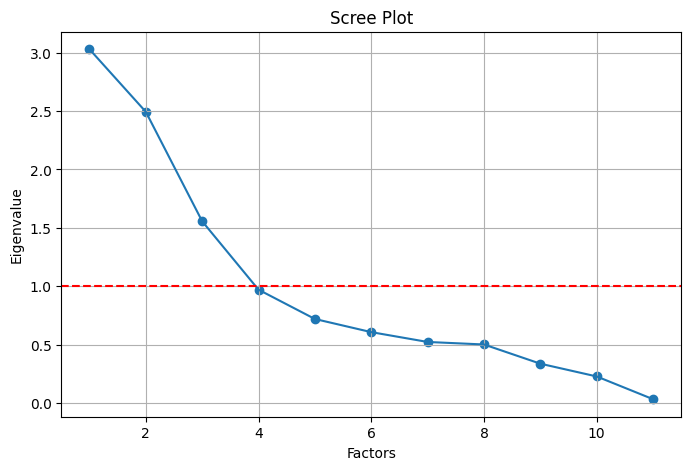

In [ ]:
fa = FactorAnalyzer(n_factors=X_scaled_df.shape[1], rotation=None)
fa.fit(X_scaled_df)
ev, v = fa.get_eigenvalues()

plt.figure(figsize=(8, 5))
plt.scatter(range(1, X_scaled_df.shape[1]+1), ev, marker='o')
plt.plot(range(1, X_scaled_df.shape[1]+1), ev)
plt.axhline(y=1, color='r', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Factors')
plt.ylabel('Eigenvalue')
plt.grid(True)
plt.show()

The number of factors to retain are 3. It is obtained by examining Factors with an eigenvalue greater than 1 (Kaiser criterion), and the "elbow" of the scree plot provides a visual confirmation of where the marginal variance explained drops off.

3. Select an extraction method

Maximum Likelihood is selected as the extraction method because of the large dataset and it provides robust parameter estimates for identifying the underlying latent constructs driving the wine's chemical makeup.

4. Select a rotation method

An oblique rotation method (Promax) is selected because the underlying latent factors of wine chemistry are expected to be correlated in the real world rather than independent.

5. Examine factor loadings

In [ ]:
n_factors = 3
fa_rotated = FactorAnalyzer(n_factors=n_factors, rotation='promax', method='ml')
fa_rotated.fit(X_scaled_df)

loadings = pd.DataFrame(fa_rotated.loadings_, index=efa_vars, columns=[f'Factor {i+1}' for i in range(n_factors)])
communalities = pd.DataFrame(fa_rotated.get_communalities(), index=efa_vars, columns=['Communalities'])
uniquenesses = pd.DataFrame(fa_rotated.get_uniquenesses(), index=efa_vars, columns=['Uniquenesses'])

print("Factor Loadings:\n", loadings)
print("\nCommunalities and Uniquenesses:\n", pd.concat([communalities, uniquenesses], axis=1))

Factor Loadings:
                       Factor 1  Factor 2  Factor 3
fixed acidity         0.703469  0.005060  0.813881
volatile acidity      0.588925  0.098139 -0.198757
citric acid          -0.094741  0.014242  0.529668
residual sugar       -0.355000  0.763879 -0.024006
chlorides             0.483891  0.199349 -0.020652
free sulfur dioxide  -0.633120  0.281596  0.064419
total sulfur dioxide -0.737251  0.330831  0.075134
density               0.418210  0.892662  0.111139
pH                    0.219487  0.051852 -0.543966
sulphates             0.458915  0.083444  0.025621
alcohol              -0.061066 -0.747208  0.071971

Communalities and Uniquenesses:
                       Communalities  Uniquenesses
fixed acidity              1.157298     -0.157298
volatile acidity           0.395968      0.604032
citric acid                0.289727      0.710273
residual sugar             0.710113      0.289887
chlorides                  0.274317      0.725683
free sulfur dioxide        0.484287 

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


6. Interpret the factors

1. Preservation Practices - free sulfur dioxide, total sulfur dioxide
2. Acidic Structure - fixed acidity, citric acid, and a strong negative loading on pH
3. Fermentation Profile - alcohol, density, and residual sugar

**Part E – Integrated Interpretation**

1. MANOVA: What distinguishes red and white wines?

Red wines are distinguished by higher volatile acidity, chlorides, and sulphates, while white wines are defined by higher total and free sulfur dioxide concentrations used for preservation.

2. PCA: What are the major dimensions of variation among the physicochemical measurements?

The major dimensions that capture the majority of the variance represent the primary axes of data variation, typically contrasting the alcohol/density profile against the acidity and sulfur dioxide profiles.

3. EFA: What latent factors appear to explain the relationships among the variables?

The relationships are explained by latent factors such as Sulfur Management, Natural Grape Acidity, and Fermentation Outcomes.

4. Comparison of PCA and EFA: Discuss similarities and differences between prin- cipal components and common factors. Identify variables that appear important in both PCA and EFA.

Both PCA and EFA highlight sulfur dioxide and acidity as critical variables. The difference is that PCA maximizes total variance explained, while EFA models the common variance to uncover interpretable, correlated latent factors.

5. Substantive interpretation: What do the findings tell us about the physico-chemical characteristics of Vinho Verde wines?

The integrated findings confirm that the physicochemical characteristics of Vinho Verde wines are not random but heavily dictated by the wine type and specific winemaking decisions. The chemical makeup is structured around preservation techniques, acidic balance, and the fermentation process

6. Limitations: Discuss at least two limitations of your analysis.

Imbalanced Data - The dataset contains a severe imbalance, 4,898 white wines vs. 1,599 red wines, which makes the multivariate centroids, principal components, and factor structures are disproportionately influenced by the characteristics of white wines.   

Limitations of Applying PCA/EFA to Chemical Variables - Physicochemical wine characteristics might interact in complex, non-linear ways during fermentation and aging, which might make linear reduction techniques oversimplify the true chemical profile of the wines.